# Titanic Famous Dataset

## Problem - Binary Classification

**Goal** : Whether a person survived the disaster or not

**Target** : **Survived**


# 1. Importing Libraries

In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

import warnings
import random

warnings.filterwarnings('ignore')

In [3]:

SEED=42
random.seed(42)
np.random.seed(42)

# 2. Data Loading & Inspection

In [4]:
df=sns.load_dataset('titanic')

In [5]:
print("dataset shape:", df.shape)
display(df.info())
df.head(5)

dataset shape: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


None

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


# 3. EDA & Feature Engineering

In [7]:
TARGET='survived'
counts=df[TARGET].value_counts()
pct=(df[TARGET].value_counts(normalize=True)*100).round(2)

class_balance=pd.DataFrame({
    'count':counts,
    'pct %':pct
})
class_balance

,count,pct %
survived,,
0,549,61.62
1,342,38.38


In [8]:
# almost 40 % people has survived the titanic disaster caring a good ratio of survival .... lol

In [9]:
quality=pd.DataFrame({
    'dtype':df.dtypes.astype(str),
    'NaN count':df.isna().sum(),
    'pct %':(df.isna().mean()*100).round(2),
    'unique' : df.nunique()
})
quality
    

,dtype,NaN count,pct %,unique
survived,int64,0,0.00,2
pclass,int64,0,0.00,3
sex,object,0,0.00,2
age,float64,177,19.87,88
sibsp,int64,0,0.00,7
parch,int64,0,0.00,7
fare,float64,0,0.00,248
embarked,object,2,0.22,3
class,category,0,0.00,3
who,object,0,0.00,3


In [12]:
numeric_col=df.select_dtypes(include='number').columns.tolist()
category_col=df.select_dtypes(include=['category','object','bool']).columns.tolist()

print("\n-----numeric columns-----")
print(numeric_col)

print("\n-----categorical columns-----")
print(category_col)


-----numeric columns-----
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

-----categorical columns-----
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


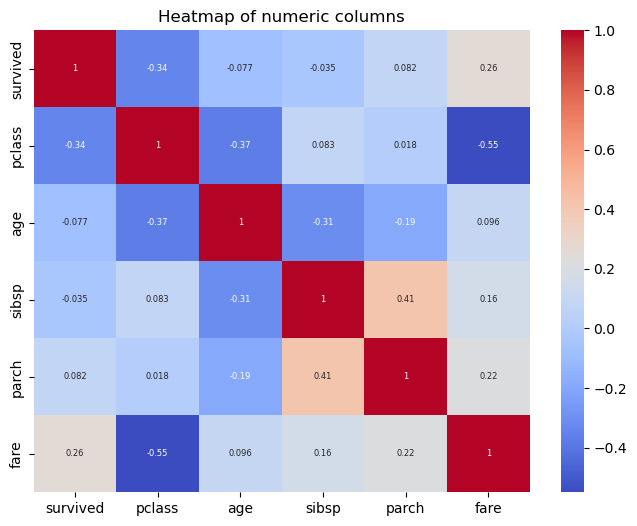

In [18]:
# plotting heatmap to show the relationship betweeen each numeric columns

plt.figure(figsize=(8,6))
corr=df[numeric_col].corr()
sns.heatmap(
    corr,
    annot=True,
    annot_kws={'size':6},
    cmap='coolwarm'
)
plt.title("Heatmap of numeric columns")
plt.show()

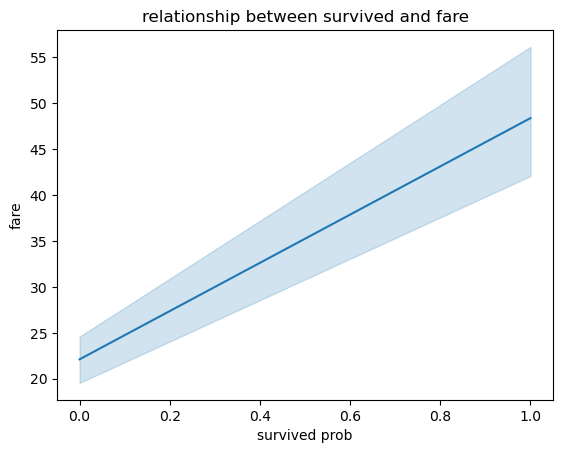

In [22]:
sns.lineplot(data=df,x='survived',y='fare')
plt.xlabel("survived prob")
plt.ylabel("fare")
plt.title("relationship between survived and fare")
plt.show()

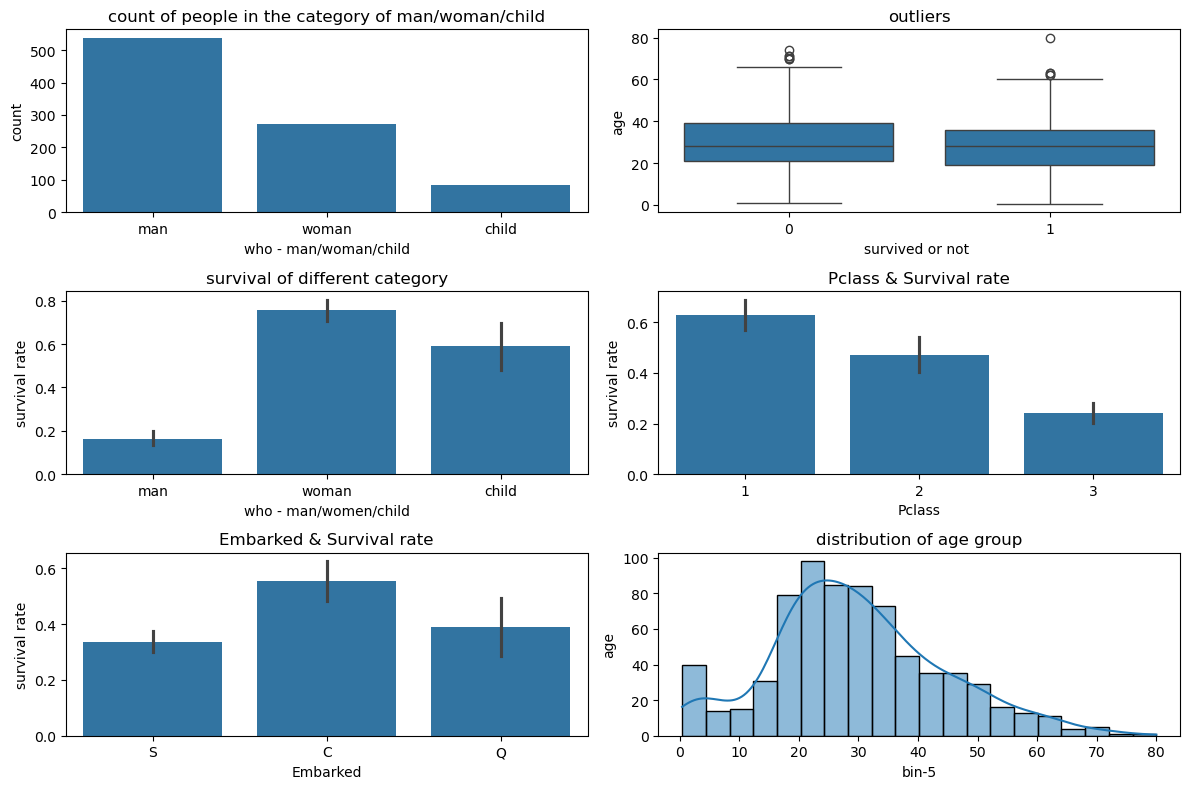

In [63]:
fig, axes=plt.subplots(3,2,figsize=(12,8))

sns.countplot(x=df['who'],ax=axes[0,0])
axes[0,0].set_title('count of people in the category of man/woman/child')
axes[0,0].set_xlabel('who - man/woman/child')
axes[0,0].set_ylabel('count')

sns.boxplot(x=df['survived'],y=df['age'],ax=axes[0,1])
axes[0,1].set_title('outliers')
axes[0,1].set_xlabel('survived or not ')
axes[0,1].set_ylabel('age')

sns.barplot(x=df['who'],y=df['survived'],ax=axes[1,0])
axes[1,0].set_title('survival of different category')
axes[1,0].set_xlabel('who - man/women/child')
axes[1,0].set_ylabel('survival rate')

sns.barplot(x=df['pclass'],y=df['survived'],ax=axes[1,1])
axes[1,1].set_title('Pclass & Survival rate')
axes[1,1].set_xlabel('Pclass')
axes[1,1].set_ylabel('survival rate')

sns.barplot(x=df['embarked'],y=df['survived'],ax=axes[2,0])
axes[2,0].set_title('Embarked & Survival rate')
axes[2,0].set_xlabel('Embarked')
axes[2,0].set_ylabel('survival rate')

sns.histplot(x=df['age'],kde=True,ax=axes[2,1])
axes[2,1].set_title('distribution of age group')
axes[2,1].set_xlabel('bin-5')
axes[2,1].set_ylabel('age')
plt.tight_layout()
plt.show()

In [ ]:
fig,axes=plt.subplots(3,2,figsize=(12,8))



plt.tight_layout()
plt.show()

In [24]:
df.head(5)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
